# CSET343 – AI in Healthcare | Lab Assignment 6
**CNN-based diagnosis on Chest X-Ray Images (Normal vs Pneumonia)**

## Setup

In [1]:
!pip -q install kagglehub scikit-image

import os, re, glob, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from joblib import Parallel, delayed
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers

warnings.filterwarnings("ignore")
SEED = 42
IMG_SIZE = 128
CLASSES = ["NORMAL", "PNEUMONIA"]   # label 0, 1
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TF:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TF: 2.20.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Task 1: Data Acquisition and Exploration

In [2]:
import kagglehub
# Public Kaggle dataset (Paul Mooney). If this fails, upload kaggle.json and use:
#   !kaggle datasets download -d paultimothymooney/chest-xray-pneumonia --unzip -p data
root = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Downloaded to:", root)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Downloaded to: /kaggle/input/chest-xray-pneumonia


Total images: 5856 (expected ~5,856-5,863)
Unique patient groups: 2790

Images per class:
 cls
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64

Class balance (%):
 cls
PNEUMONIA    72.97
NORMAL       27.03
Name: count, dtype: float64


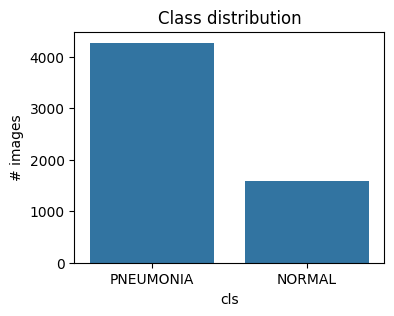

In [3]:
# The dataset ships pre-split into train/val/test (val has only 16 images) and some
# copies contain a duplicated nested folder. We pool everything, de-duplicate by
# (class, filename) and re-split ourselves as the assignment requires (70/15/15).
records = {}
for cls in CLASSES:
    for p in glob.glob(os.path.join(root, "**", cls, "*.*"), recursive=True):
        if "__MACOSX" in p or not p.lower().endswith((".jpeg", ".jpg", ".png")):
            continue
        records[(cls, os.path.basename(p))] = p

df = pd.DataFrame([{"path": p, "cls": k[0], "label": CLASSES.index(k[0]), "fname": k[1]}
                   for k, p in records.items()])

# Patient-level group id: many images belong to the same patient. A random image-level
# split would leak the same patient into train and test and inflate the scores.
def group_id(row):
    f = row.fname
    m = re.search(r"person(\d+)", f) if row.cls == "PNEUMONIA" else re.search(r"IM-(\d+)", f)
    return f"{row.cls}_{m.group(1)}" if m else f"{row.cls}_{f}"
df["group"] = df.apply(group_id, axis=1)

print("Total images:", len(df), "(expected ~5,856-5,863)")
print("Unique patient groups:", df["group"].nunique())
counts = df["cls"].value_counts()
print("\nImages per class:\n", counts)
print("\nClass balance (%):\n", (counts / len(df) * 100).round(2))

plt.figure(figsize=(4, 3))
sns.barplot(x=counts.index, y=counts.values)
plt.title("Class distribution"); plt.ylabel("# images"); plt.show()

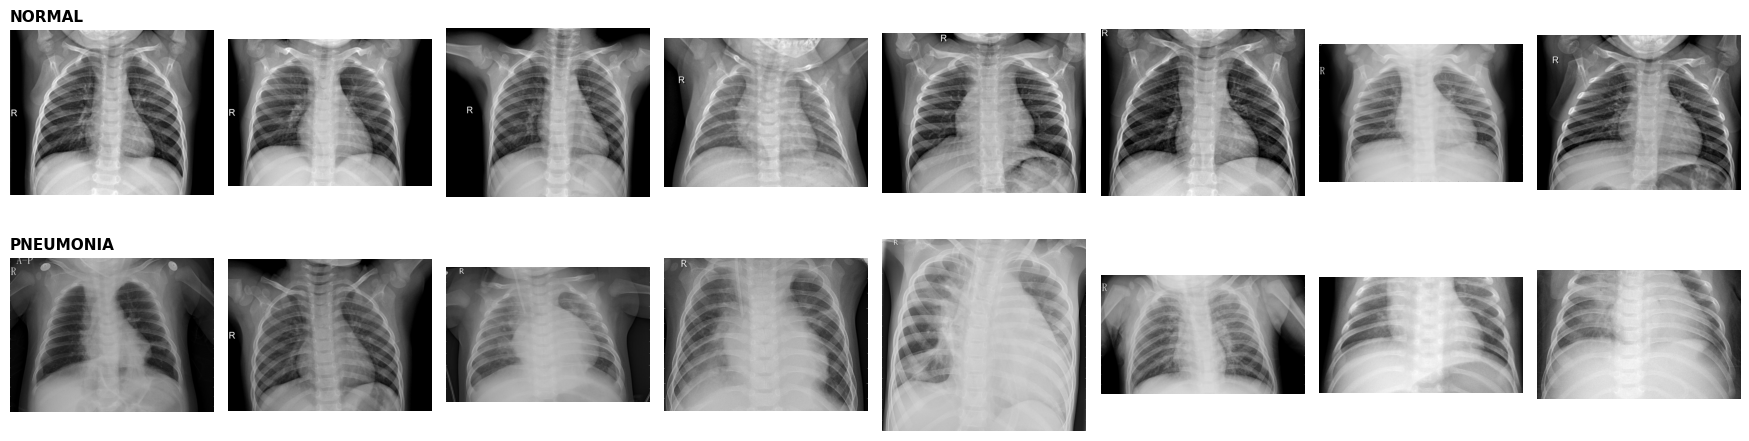

In [4]:
# 8 random samples per class
N_SHOW = 8
fig, axes = plt.subplots(2, N_SHOW, figsize=(2.2 * N_SHOW, 5))
for r, cls in enumerate(CLASSES):
    sample = df[df.cls == cls].sample(N_SHOW, random_state=SEED)
    for c, p in enumerate(sample.path):
        axes[r, c].imshow(Image.open(p).convert("L"), cmap="gray")
        axes[r, c].axis("off")
        if c == 0: axes[r, c].set_title(cls, loc="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## Task 2: Preprocessing, Feature Extraction, Split

In [5]:
def load_img(p):
    return np.asarray(Image.open(p).convert("L").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.uint8)

X = np.stack(Parallel(n_jobs=-1)(delayed(load_img)(p) for p in df.path))   # (N,128,128) grayscale
y = df.label.values
groups = df.group.values
print("Image tensor:", X.shape, X.dtype)

Image tensor: (5856, 128, 128) uint8


In [6]:
# ---- Hand-crafted features: HOG + LBP + GLCM ----
LBP_P, LBP_R = 8, 1
GLCM_LEVELS = 32
GLCM_PROPS = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]

def extract_features(img):
    f_hog = hog(img, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), block_norm="L2-Hys")
    lbp = local_binary_pattern(img, LBP_P, LBP_R, method="uniform")
    f_lbp, _ = np.histogram(lbp, bins=np.arange(0, LBP_P + 3), density=True)      # 10 bins
    q = (img // (256 // GLCM_LEVELS)).astype(np.uint8)                            # quantise to 32 levels
    glcm = graycomatrix(q, distances=[1, 3], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                        levels=GLCM_LEVELS, symmetric=True, normed=True)
    f_glcm = np.concatenate([graycoprops(glcm, p).ravel() for p in GLCM_PROPS])
    return f_hog, f_lbp, f_glcm

out = Parallel(n_jobs=-1)(delayed(extract_features)(im) for im in X)
F_hog  = np.array([o[0] for o in out])
F_lbp  = np.array([o[1] for o in out])
F_glcm = np.array([o[2] for o in out])
F_all  = np.hstack([F_hog, F_lbp, F_glcm])
print(f"HOG {F_hog.shape} | LBP {F_lbp.shape} | GLCM {F_glcm.shape} | Combined {F_all.shape}")

HOG (5856, 1764) | LBP (5856, 10) | GLCM (5856, 48) | Combined (5856, 1822)


In [7]:
# ---- 70 / 15 / 15 split (patient-level, so no patient appears in two splits) ----
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
tr_idx, tmp_idx = next(gss1.split(X, y, groups))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
va_rel, te_rel = next(gss2.split(X[tmp_idx], y[tmp_idx], groups[tmp_idx]))
va_idx, te_idx = tmp_idx[va_rel], tmp_idx[te_rel]

assert not (set(groups[tr_idx]) & set(groups[va_idx]))
assert not (set(groups[tr_idx]) & set(groups[te_idx]))
assert not (set(groups[va_idx]) & set(groups[te_idx]))

for name, idx in [("Train", tr_idx), ("Val", va_idx), ("Test", te_idx)]:
    print(f"{name:5s}: {len(idx):5d} ({len(idx)/len(y):.1%}) | pneumonia share = {y[idx].mean():.1%}")

Xtr, Xva, Xte = X[tr_idx], X[va_idx], X[te_idx]
ytr, yva, yte = y[tr_idx], y[va_idx], y[te_idx]
gtr = groups[tr_idx]
Ftr, Fva, Fte = F_all[tr_idx], F_all[va_idx], F_all[te_idx]

Train:  4086 (69.8%) | pneumonia share = 73.2%
Val  :   877 (15.0%) | pneumonia share = 72.5%
Test :   893 (15.2%) | pneumonia share = 72.5%


## Task 3: Models, Cross-Validation, Evaluation
- **CNN** (baseline, raw pixels) – hyperparameters tuned with 3-fold patient-grouped CV.
- **Classical baselines** on the HOG+LBP+GLCM feature vector (Logistic Regression, SVM, Random Forest) – tuned with 5-fold patient-grouped CV. These are the comparison classifiers.
- Validation set is used for CNN early stopping; classical models use CV instead. **Test set is touched once, at the end.**

In [8]:
def compute_metrics(y_true, y_pred, y_score):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred),
            "AUROC": roc_auc_score(y_true, y_score)}

results = {}   # name -> dict(y_pred, y_score)

### 3a. CNN – cross-validated hyperparameter search

In [9]:
augment = models.Sequential([layers.RandomRotation(0.05), layers.RandomZoom(0.1),
                             layers.RandomTranslation(0.05, 0.05)], name="augment")

def build_cnn(lr=1e-3, dropout=0.3, filters=(32, 64, 128)):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 1))
    x = layers.Rescaling(1. / 255)(inp)
    x = augment(x)                         # active only during training
    for f in filters:
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    m = models.Model(inp, out)
    m.compile(optimizer=optimizers.Adam(lr), loss="binary_crossentropy",
              metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return m

def class_weights(labels):
    n, k = len(labels), 2
    return {c: n / (k * (labels == c).sum()) for c in (0, 1)}   # counters the Normal/Pneumonia imbalance

def to4d(a): return a[..., None]

In [10]:
param_grid = [{"lr": lr, "dropout": d} for lr in (1e-3, 3e-4) for d in (0.3, 0.5)]
CV_EPOCHS = 6
sgkf = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
folds = list(sgkf.split(Xtr, ytr, gtr))

cv_rows = []
for params in param_grid:
    aucs = []
    for k, (a, b) in enumerate(folds):
        tf.keras.backend.clear_session()
        m = build_cnn(**params)
        h = m.fit(to4d(Xtr[a]), ytr[a], validation_data=(to4d(Xtr[b]), ytr[b]),
                  epochs=CV_EPOCHS, batch_size=32, class_weight=class_weights(ytr[a]), verbose=0)
        aucs.append(max(h.history["val_auc"]))
    cv_rows.append({**params, "cv_auc_mean": np.mean(aucs), "cv_auc_std": np.std(aucs)})
    print(params, f"-> CV AUROC {np.mean(aucs):.4f} ± {np.std(aucs):.4f}")

cv_df = pd.DataFrame(cv_rows).sort_values("cv_auc_mean", ascending=False)
display(cv_df)
best_params = {k: cv_df.iloc[0][k] for k in ("lr", "dropout")}
print("Best CNN params:", best_params)

{'lr': 0.001, 'dropout': 0.3} -> CV AUROC 0.8978 ± 0.0471
{'lr': 0.001, 'dropout': 0.5} -> CV AUROC 0.9131 ± 0.0439
{'lr': 0.0003, 'dropout': 0.3} -> CV AUROC 0.9364 ± 0.0175
{'lr': 0.0003, 'dropout': 0.5} -> CV AUROC 0.9245 ± 0.0248


,lr,dropout,cv_auc_mean,cv_auc_std
2,0.0003,0.3,0.936441,0.017538
3,0.0003,0.5,0.924526,0.024825
1,0.0010,0.5,0.913120,0.043918
0,0.0010,0.3,0.897827,0.047148


Best CNN params: {'lr': np.float64(0.0003), 'dropout': np.float64(0.3)}


### 3b. CNN – final training

Epoch 1/30
128/128 - 11s - 88ms/step - accuracy: 0.7954 - auc: 0.8926 - loss: 0.4185 - val_accuracy: 0.7252 - val_auc: 0.6121 - val_loss: 0.5878 - learning_rate: 3.0000e-04
Epoch 2/30
128/128 - 7s - 51ms/step - accuracy: 0.8502 - auc: 0.9285 - loss: 0.3384 - val_accuracy: 0.7252 - val_auc: 0.6958 - val_loss: 0.7195 - learning_rate: 3.0000e-04
Epoch 3/30
128/128 - 6s - 48ms/step - accuracy: 0.8644 - auc: 0.9430 - loss: 0.3043 - val_accuracy: 0.7252 - val_auc: 0.7584 - val_loss: 1.2476 - learning_rate: 3.0000e-04
Epoch 4/30
128/128 - 10s - 81ms/step - accuracy: 0.8791 - auc: 0.9517 - loss: 0.2818 - val_accuracy: 0.7252 - val_auc: 0.9273 - val_loss: 0.9652 - learning_rate: 3.0000e-04
Epoch 5/30
128/128 - 6s - 47ms/step - accuracy: 0.8882 - auc: 0.9607 - loss: 0.2577 - val_accuracy: 0.8290 - val_auc: 0.9240 - val_loss: 0.3533 - learning_rate: 1.5000e-04
Epoch 6/30
128/128 - 6s - 48ms/step - accuracy: 0.8899 - auc: 0.9638 - loss: 0.2478 - val_accuracy: 0.5895 - val_auc: 0.9187 - val_loss: 0

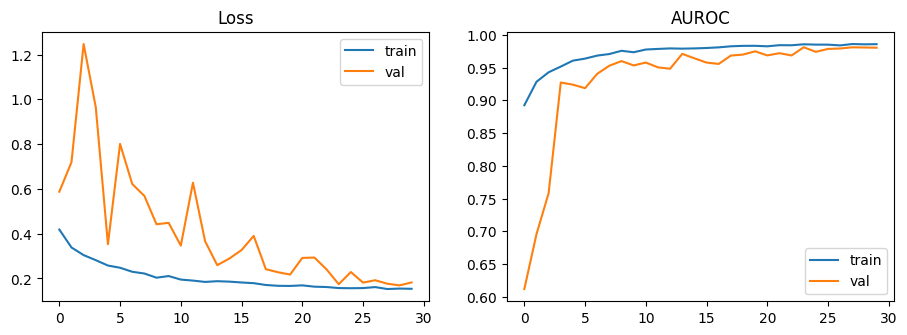

In [11]:
tf.keras.backend.clear_session()
cnn = build_cnn(**best_params)
cbs = [callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6, restore_best_weights=True),
       callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)]
hist = cnn.fit(to4d(Xtr), ytr, validation_data=(to4d(Xva), yva), epochs=30, batch_size=32,
               class_weight=class_weights(ytr), callbacks=cbs, verbose=2)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist.history["auc"], label="train"); ax[1].plot(hist.history["val_auc"], label="val"); ax[1].set_title("AUROC"); ax[1].legend()
plt.show()

cnn_score = cnn.predict(to4d(Xte), verbose=0).ravel()
results["CNN"] = {"y_pred": (cnn_score >= 0.5).astype(int), "y_score": cnn_score}

### 3c. Classical classifiers on HOG + LBP + GLCM features (CV-tuned)

In [12]:
cv5 = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(Ftr, ytr, gtr))

searches = {
    "LogReg (HOG+LBP+GLCM)": (Pipeline([("sc", StandardScaler()),
                                        ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
                              {"clf__C": [0.01, 0.1, 1]}),
    "SVM-RBF (HOG+LBP+GLCM)": (Pipeline([("sc", StandardScaler()),
                                         ("clf", SVC(kernel="rbf", class_weight="balanced"))]),
                               {"clf__C": [1, 10], "clf__gamma": ["scale", 0.001]}),
    "RandomForest (HOG+LBP+GLCM)": (RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
                                    {"n_estimators": [200, 400], "max_depth": [None, 20]}),
}

for name, (est, grid) in searches.items():
    gs = GridSearchCV(est, grid, scoring="roc_auc", cv=cv5, n_jobs=-1)
    gs.fit(Ftr, ytr)
    print(f"{name}: best={gs.best_params_} | CV AUROC={gs.best_score_:.4f}")
    best = gs.best_estimator_
    score = best.predict_proba(Fte)[:, 1] if hasattr(best, "predict_proba") else best.decision_function(Fte)
    results[name] = {"y_pred": best.predict(Fte), "y_score": score}

LogReg (HOG+LBP+GLCM): best={'clf__C': 0.01} | CV AUROC=0.9895
SVM-RBF (HOG+LBP+GLCM): best={'clf__C': 10, 'clf__gamma': 'scale'} | CV AUROC=0.9899
RandomForest (HOG+LBP+GLCM): best={'max_depth': 20, 'n_estimators': 400} | CV AUROC=0.9820


### 3d. Test-set evaluation and comparison

,Accuracy,Precision,Recall,F1,AUROC
SVM-RBF (HOG+LBP+GLCM),0.9653,0.9768,0.9753,0.9760,0.9937
LogReg (HOG+LBP+GLCM),0.9630,0.9827,0.9660,0.9743,0.9917
RandomForest (HOG+LBP+GLCM),0.9485,0.9574,0.9722,0.9647,0.9869
CNN,0.9373,0.9789,0.9335,0.9557,0.9850


Best by AUROC: SVM-RBF (HOG+LBP+GLCM)  |  Best by F1: SVM-RBF (HOG+LBP+GLCM)  |  Best by Recall: SVM-RBF (HOG+LBP+GLCM)


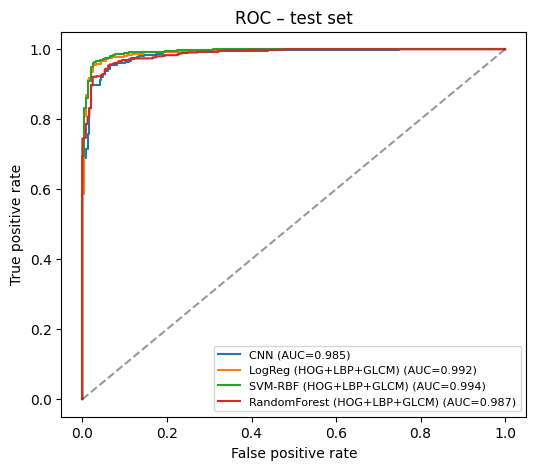

In [13]:
table = pd.DataFrame({n: compute_metrics(yte, r["y_pred"], r["y_score"]) for n, r in results.items()}).T
table = table.sort_values("AUROC", ascending=False).round(4)
display(table)
best_name = table.index[0]
print(f"Best by AUROC: {best_name}  |  Best by F1: {table['F1'].idxmax()}  |  Best by Recall: {table['Recall'].idxmax()}")

# ROC curves
plt.figure(figsize=(6, 5))
for n, r in results.items():
    fpr, tpr, _ = roc_curve(yte, r["y_score"])
    plt.plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(yte, r['y_score']):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=.4)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC – test set"); plt.legend(fontsize=8)
plt.show()

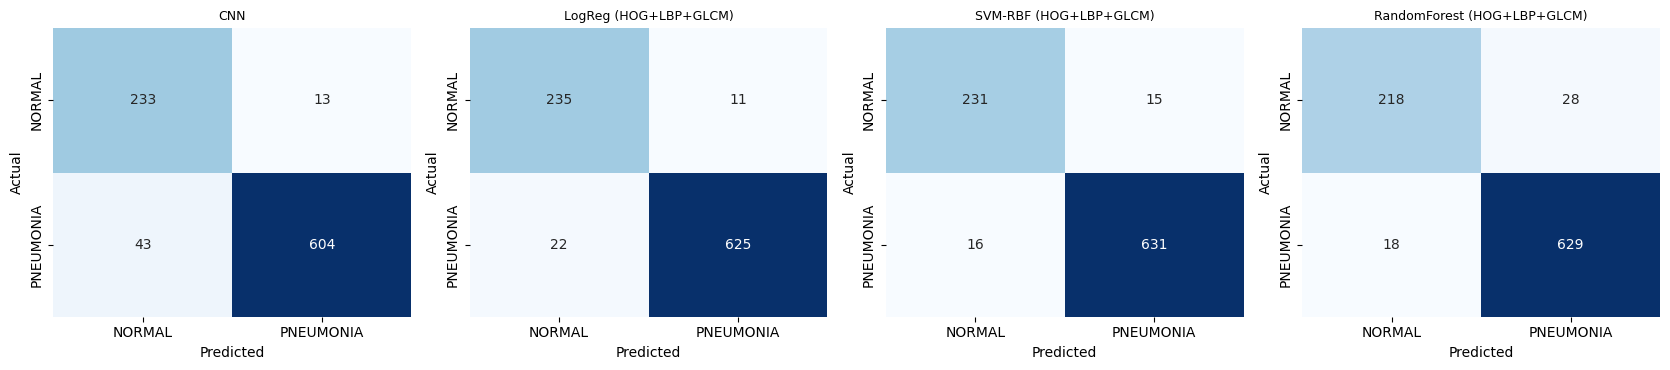

CNN                            TN= 233 FP=  13 FN=  43 TP= 604 | FP rate (Normal called Pneumonia)=5.3% | FN rate (missed Pneumonia)=6.6%
LogReg (HOG+LBP+GLCM)          TN= 235 FP=  11 FN=  22 TP= 625 | FP rate (Normal called Pneumonia)=4.5% | FN rate (missed Pneumonia)=3.4%
SVM-RBF (HOG+LBP+GLCM)         TN= 231 FP=  15 FN=  16 TP= 631 | FP rate (Normal called Pneumonia)=6.1% | FN rate (missed Pneumonia)=2.5%
RandomForest (HOG+LBP+GLCM)    TN= 218 FP=  28 FN=  18 TP= 629 | FP rate (Normal called Pneumonia)=11.4% | FN rate (missed Pneumonia)=2.8%


In [14]:
# Confusion matrices for every model
n = len(results)
fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 3.8))
for ax, (name, r) in zip(np.atleast_1d(axes), results.items()):
    cm = confusion_matrix(yte, r["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASSES, yticklabels=CLASSES)
    ax.set_title(name, fontsize=9); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

for name, r in results.items():
    tn, fp, fn, tp = confusion_matrix(yte, r["y_pred"]).ravel()
    print(f"{name:30s} TN={tn:4d} FP={fp:4d} FN={fn:4d} TP={tp:4d} | "
          f"FP rate (Normal called Pneumonia)={fp/(fp+tn):.1%} | FN rate (missed Pneumonia)={fn/(fn+tp):.1%}")

SVM-RBF (HOG+LBP+GLCM): 15 false positives, 16 false negatives


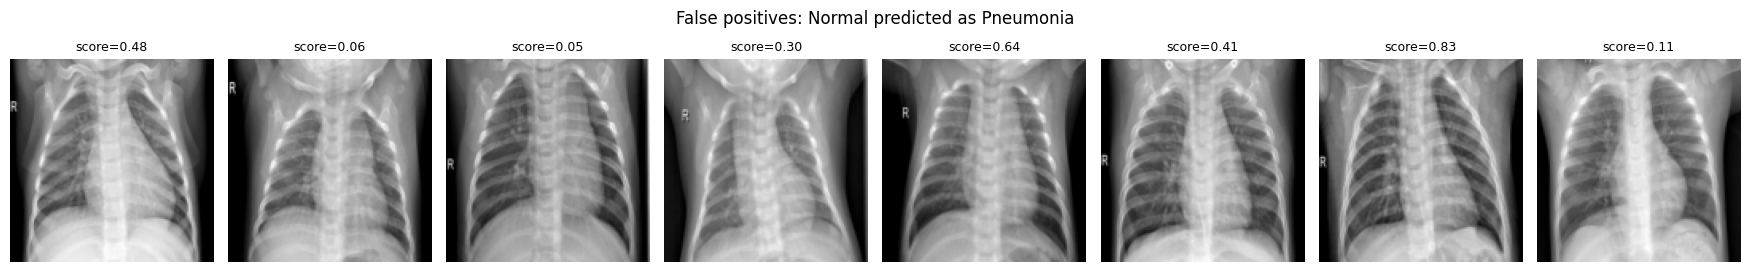

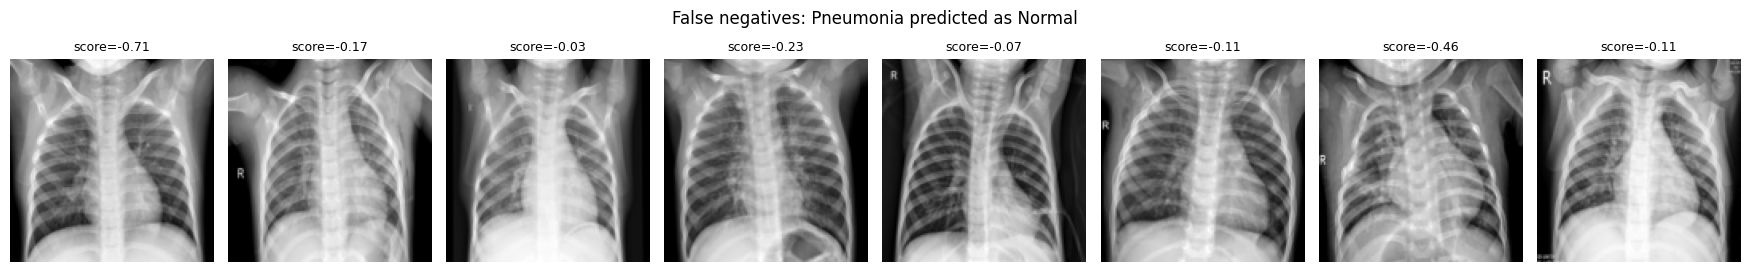

In [15]:
# Look at the actual misclassified images of the best model
pred = results[best_name]["y_pred"]; score = results[best_name]["y_score"]
fp_idx = np.where((yte == 0) & (pred == 1))[0]
fn_idx = np.where((yte == 1) & (pred == 0))[0]
print(f"{best_name}: {len(fp_idx)} false positives, {len(fn_idx)} false negatives")

def show(idxs, title, k=8):
    idxs = idxs[:k]
    if len(idxs) == 0: print(f"No {title}"); return
    fig, axes = plt.subplots(1, len(idxs), figsize=(2.2 * len(idxs), 2.8))
    for ax, i in zip(np.atleast_1d(axes), idxs):
        ax.imshow(Xte[i], cmap="gray"); ax.axis("off"); ax.set_title(f"score={score[i]:.2f}", fontsize=9)
    plt.suptitle(title); plt.tight_layout(); plt.show()

show(fp_idx, "False positives: Normal predicted as Pneumonia")
show(fn_idx, "False negatives: Pneumonia predicted as Normal")

### Discussion (write this from YOUR results after running)
Fill in using the confusion matrices and misclassified images above. Do not submit this text unedited.

1. **Best performer:** which model, and by which metric? Is the gap to the runner-up larger than what a single test split can resolve (the test set is ~880 images, so a 1% gap is only ~9 images)?
2. **Misclassifications:** which error dominates, FP or FN? In a screening setting a missed pneumonia (FN) costs more than a false alarm, so recall matters more than accuracy here.
3. **Why errors happen:** look at the plotted images. Are the FPs faint/low-contrast or with other opacities/devices? Are the FNs subtle or early infiltrates? Only claim what you actually see.
4. **Imbalance:** ~73% of images are Pneumonia, so accuracy alone is misleading. A model that always predicts Pneumonia scores ~73%.
5. **Limitations:** single dataset, paediatric patients only, 128×128 downsampling loses fine detail, no external validation.